In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))

### Preprocessing du Dataset

##### 1. Importation des données et vérification des extensions

##### 2. Création d'une DataFrame
- `path` de l'image
- `target`
- `extensions`

##### 3. Analyse de data et visualisation
- Visualisation du count de chaque catégorie

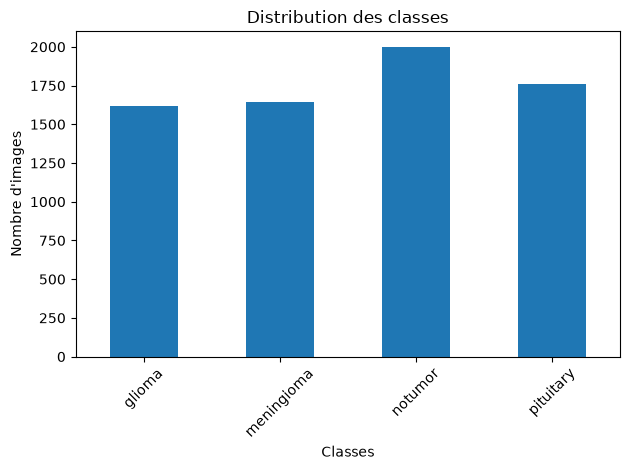

In [5]:
from src.data import build_manifest, analyze_classes 

manifest = build_manifest("../data")
analyze_classes(manifest)

manifest.to_csv(
        "../artifacts/data/manifest.csv",
        index=False,
    )

### Détection des doublons avec SHA-256

Cette étape permet d'identifier les images dupliquées dans le dataset grâce à leur empreinte SHA-256.

- **Détection :** identifier les images qui possèdent la même empreinte SHA-256.
- **Filtrage :** conserver uniquement les groupes de doublons appartenant à la même classe (`label`).
- **Sauvegarde :** enregistrer les résultats dans un fichier CSV pour faciliter leur analyse.

Cette étape contribue à améliorer la qualité du dataset avant le preprocessing et l'entraînement du modèle.

In [4]:
output_dir = Path("../artifacts/test_data")
output_dir.mkdir(parents=True, exist_ok=True)

duplicates = manifest[manifest.duplicated("sha256", keep=False)]

duplicates_same_class = duplicates[
    duplicates.groupby("sha256")["label"].transform("nunique") == 1
].copy()

duplicates_same_class.to_csv(output_dir/"data.csv",index=False)

### Division de la dataset et encodage des labels

- **Split de la dataset :** séparation du dataset en trois ensembles : entraînement (`train_df`), validation (`val_df`) et test (`test_df`), afin d'entraîner le modèle, d'ajuster ses paramètres et d'évaluer ses performances sur des données non vues.

- **Encodage des labels :** transformation des catégories textuelles en valeurs numériques exploitables par le modèle de Machine Learning. Cette fonction retourne également `class_names`, qui contient les noms des classes pour conserver la correspondance entre les labels numériques et les catégories originales.

In [6]:
from src.preprocessing import split_dataset, load_image , encode_labels, create_tf_dataset

train_df, val_df, test_df = split_dataset(manifest)

train_df, val_df, test_df, class_names = encode_labels(
    train_df, val_df, test_df
)

### Création des datasets TensorFlow

- Création des datasets d'entraînement, de validation et de test à partir des DataFrames obtenues après le preprocessing.
- Application du mélange aléatoire (`shuffle=True`) uniquement sur le dataset d'entraînement afin d'améliorer l'apprentissage du modèle.
- Préparation des données dans un format compatible avec TensorFlow pour faciliter l'entraînement, la validation et l'évaluation du modèle.

In [7]:
train_ds = create_tf_dataset(train_df, shuffle=True)
val_ds = create_tf_dataset(val_df)
test_ds = create_tf_dataset(test_df)


### Construction du modèle CNN

Nous construisons un modèle CNN pour classifier les images IRM cérébrales.

- **Input Shape :** images de 224 × 224 pixels avec 3 canaux RGB.
- **Num Classes :** nombre de catégories à prédire.
- **Model :** modèle prêt pour la compilation et l'entraînement.

In [8]:
from src.model import build_cnn

model = build_cnn(
    input_shape=(224, 224, 3),
    num_classes=len(class_names),
)

# model.summary()

### Compilation du modèle CNN

Nous configurons le modèle avant son entraînement.

- **Optimizer (Adam) :** ajuste les poids du modèle pour améliorer ses performances.
- **Learning Rate (0.001) :** définit la vitesse d'apprentissage.
- **Loss :** mesure l'erreur entre les prédictions et les vraies classes.
- **Accuracy :** mesure le pourcentage de prédictions correctes.

In [9]:
from tensorflow import keras

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### Entraînement du modèle CNN

Nous entraînons le modèle sur les données d'entraînement et validons ses performances à chaque époque.

- **train_ds :** données d'entraînement.
- **val_ds :** données de validation.
- **num_classes :** nombre de catégories à classifier.
- **output_dir :** dossier où le meilleur modèle sera sauvegardé.
- **epochs = 30 :** nombre maximal de cycles d'entraînement.
- **best_model :** meilleur modèle entraîné.
- **history :** historique des performances.
- **duration :** durée totale de l'entraînement en secondes.

In [10]:
from src.train import train_model

num_classes = len(class_names)

best_model, history, duration = train_model(
    train_ds=train_ds,
    val_ds=val_ds,
    num_classes=num_classes,
    output_dir="artifacts/models",
    epochs=30,
)

print(f"Training duration: {duration:.2f} seconds")

Epoch 1/30


c:\Users\errak\Desktop\BrainScan\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - accuracy: 0.4089 - loss: 1.1988
Epoch 1: val_loss improved from None to 1.13599, saving model to artifacts\models\best_model.keras

Epoch 1: finished saving model to artifacts\models\best_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 116s 702ms/step - accuracy: 0.4089 - loss: 1.1988 - val_accuracy: 0.4141 - val_loss: 1.1360 - learning_rate: 0.0010
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - accuracy: 0.5504 - loss: 1.0104
Epoch 2: val_loss improved from 1.13599 to 0.94071, saving model to artifacts\models\best_model.keras

Epoch 2: finished saving model to artifacts\models\best_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 108s 676ms/step - accuracy: 0.5504 - loss: 1.0104 - val_accuracy: 0.6144 - val_loss: 0.9407 - learning_rate: 0.0010
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - accuracy: 0.6442 - loss: 0.8818
Epoch 3: val_loss improved from 0.94071 to 0.81765, saving model to artifacts\models\best_model.keras

Epoch 3: finish

In [ ]:
from src.evaluate import (
    load_best_model,
    evaluate_model,
    plot_training_history,
    get_predictions,
    plot_confusion_matrix,
    print_classification_report,
)

### Évaluation du modèle

Nous chargeons le meilleur modèle sauvegardé et évaluons ses performances sur les données de test.

- **load_best_model() :** charge le meilleur modèle entraîné.
- **test_ds :** données de test utilisées pour évaluer le modèle.
- **test_metrics :** contient les métriques d'évaluation, comme la perte (*loss*) et l'accuracy.

In [ ]:
best_model = load_best_model()
test_metrics = evaluate_model(best_model, test_ds)

###  Visualisation des courbes d'apprentissage

Nous visualisons l'évolution de l'accuracy et de la loss pendant l'entraînement et la validation afin d'analyser les performances du modèle et de détecter un éventuel overfitting.

In [ ]:
plot_training_history(history)


###  Génération des prédictions

Nous utilisons le meilleur modèle entraîné pour prédire les classes des images IRM du dataset de test.

- **y_true :** vraies classes des images.
- **y_pred :** classes prédites par le modèle.
- **y_prob :** probabilités prédites pour chaque classe.

In [ ]:
y_true, y_pred, y_prob = get_predictions(
    best_model,
    test_ds,
)

###  Matrice de confusion

Nous visualisons la matrice de confusion pour comparer les classes réelles aux classes prédites et identifier les erreurs de classification du modèle.

In [ ]:
cm = plot_confusion_matrix(
    y_true,
    y_pred,
    class_names,
)

###  Rapport de classification

Nous générons un rapport pour évaluer les performances du modèle à l'aide des métriques suivantes :

- **Precision :** fiabilité des prédictions positives.
- **Recall :** capacité à détecter les images d'une classe.
- **F1-score :** équilibre entre la précision et le recall.
- **Support :** nombre d'images réelles par classe.

In [ ]:
report = print_classification_report(
    y_true,
    y_pred,
    class_names,
)


In [3]:
from src.save import convert_keras_to_h5

h5_path = convert_keras_to_h5(
    input_path="../notebooks/artifacts/models/best_model.keras",
    output_path="../artifacts/models/best_model.h5",
)

Modèle converti avec succès : C:\Users\errak\Desktop\BrainScan\artifacts\models\best_model.h5


In [2]:
from src.predict import load_saved_model

best_model = load_saved_model()

Modèle chargé : C:\Users\errak\Desktop\BrainScan\artifacts\models\best_model.h5


In [8]:
from src.predict import predict_image

class_names = sorted(manifest["label"].unique().tolist())


result = predict_image(
    path=r"../data/pituitary/Te-pi_0010.jpg",
    model=best_model,
    class_names=class_names,
)

print("Classe prédite :", result["predicted_class"])
print("Confiance       :", f'{result["confidence"]:.2%}')
print("Probabilités    :", result["probabilities"])

Classe prédite : pituitary
Confiance       : 83.52%
Probabilités    : [0.0022265815641731024, 0.15456287562847137, 0.008028530515730381, 0.8351820111274719]
